# Flickr Trip identification

Identifies photo trips per user (24 h gap rule) for the RQ analyses. Belongs to RQ preparation,
NOT data preprocessing.

**Inputs:**
- `data/Flickr/clef_labels/flickr_clef_analysis.csv` — Clef activity labels, LONG format
  (one row per image x activity; built by `scripts/RQs_analysis/build_clef_analysis_tables.py`).
  `accompany_type` / `structural_activity` are per-image attributes; `activity` is grouped to a
  per-image list before trip building.
- `data/Flickr/flickr_finland_state_lands.gpkg` — photo points on state-owned lands (geometry
  source, read with geopandas; same file the original cleaning notebook used)
- `data/boundaries/` — Finland, state-owned lands, nature reserves, national parks, wilderness areas

**Outputs:**
- `data/Flickr/flickr_trips.gpkg` — activity trips (activity-level aggregation, with
  nature_reserve / national_park / wilderness_area / commercial_forest flags)
- `data/Flickr/flickr_trips_all.gpkg` — all trips (time-gap only, no activity filter)
- `figures/` — trip EDA figures (activity co-occurrence, temporal patterns, spatial maps)

**IMPORTANT — on-disk trip files are kept as-is.** The existing `flickr_trips.gpkg` /
`flickr_trips_all.gpkg` were built from the archived Qwen3-VL labels (project decision: keep
the old files). This notebook now documents how to rebuild them from the Clef labels; only
re-run the `to_file` cells if a rebuild from Clef labels is explicitly requested.

**Flag correction (2026-10-21):** the `commercial_forest` flag is now defined as a spatial
join against `MH kiinteistot.gpkg` filtered to `Admin_level == 'Metsätalous'` (Metsähallitus
Forestry profit center ≈ state multiple-use/commercial forests), replacing the old
subtraction-based definition (state land minus reserves minus wilderness areas), which
overestimated commercial forest by including Luontopalvelut and Kiinteistökehitys properties.
The `nature_reserve` / `national_park` / `wilderness_area` flags are unchanged, and the
on-disk trip files keep their ACTIVITIES from the old LLM run (project decision); only the
`commercial_forest` flag in `flickr_trips.gpkg` was corrected in place.

**EDA scope:** activity level only. The archived per-image label table (with `sub_activity`,
`type`, `age_group`, `gender`) no longer exists; the Clef labels carry `activity`,
`structural_activity`, `accompany_type` only.

# Load packages

In [1]:
import pandas as pd
import geopandas as gpd

import json
from pathlib import Path
from tqdm import tqdm

# Read data

## Read Flickr data

In [2]:
# Read the geopackage
gdf_flickr = gpd.read_file('../../data/Flickr/flickr_finland_state_lands.gpkg')

# Convert date_taken to datetime and extract year, month, and date
gdf_flickr['date_taken'] = pd.to_datetime(gdf_flickr['date_taken'], unit='s')

gdf_flickr['year'] = gdf_flickr['date_taken'].dt.year
gdf_flickr['month'] = gdf_flickr['date_taken'].dt.month
gdf_flickr['date'] = gdf_flickr['date_taken'].dt.date

gdf_flickr = gdf_flickr[gdf_flickr['year']>=2018]

gdf_flickr.shape

(15471, 19)

In [3]:
# Read Clef activity labels (LONG format: one row per image x activity)
# (built by scripts/RQs_analysis/build_clef_analysis_tables.py)
df_clef = pd.read_csv('../../data/Flickr/clef_labels/flickr_clef_analysis.csv')

# structural_activity / accompany_type are per-image attributes -> collapse to one row per image
# (drop the raw 'activity' column so the per-image activity LIST below keeps the name 'activity')
df_img_attrs = df_clef.drop_duplicates('image_id').drop(columns='activity')

# activity list per image (images without a label simply get no row -> NaN after the join)
df_img_activity = (
    df_clef[~df_clef['activity'].isna()]
    .groupby('image_id')['activity']
    .apply(list)
    .reset_index()
)

df_inf = df_img_attrs.merge(df_img_activity, on='image_id', how='left')
df_inf.shape

(3365, 4)

## Read boundaries

In [4]:
# Read Finland boundary shapefile
gdf_finland = gpd.read_file('../../data/boundaries/Finland_shapefile/Finland_boundaries.shp')
gdf_finland.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [5]:
# Read state-owned lands boundary
gdf_state_lands = gpd.read_file('../../data/boundaries/MH kiinteistot.gpkg')
gdf_state_lands.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [6]:
# Read state-owned nature reserves boundary
gdf_state_nature_reserves = gpd.read_file('../../data/boundaries/luonnonsuojelualueet_valtio/LsAlueValtio.shp')
gdf_state_nature_reserves.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [7]:
# Read national parks boundary
gdf_national_parks = gpd.read_file('../../data/boundaries/finnish_national_parks_syke_2024.gpkg')
gdf_national_parks.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [8]:
# Read wilderness areas boundary
gdf_wilderness = gpd.read_file('../../data/boundaries/luonnonsuojelualueet_eramaa/LsAlueEramaa.shp')
gdf_wilderness.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

# Identify trips

## Activity trips

In [9]:
import pandas as pd
import geopandas as gpd

# =========================================================
# 1. PREPARE DATA
# =========================================================

gdf_flickr['date_taken'] = pd.to_datetime(gdf_flickr['date_taken'])

# ---------------------------------------------------------
# Helper functions
# ---------------------------------------------------------

def most_common(series):
    series = series.dropna()
    if len(series) == 0:
        return None
    return series.mode().iloc[0]

# =========================================================
# 3. df_inf IS ALREADY ONE ROW PER IMAGE
#    (activity = list of Clef labels; NaN = unlabeled image)
# =========================================================

# =========================================================
# 4. JOIN EVERYTHING TO FLICKR DATA
# =========================================================

gdf = (
    gdf_flickr
    .merge(
        df_inf,
        left_on='id',
        right_on='image_id',
        how='left'
    )
)

# =========================================================
# 5. IDENTIFY TRIPS
# =========================================================

gdf = gdf.sort_values(['user_id', 'date_taken'])

# Time difference between consecutive photos
gdf['time_diff_hours'] = (
    gdf.groupby('user_id')['date_taken']
    .diff()
    .dt.total_seconds() / 3600
)

# Start a new trip if interval > 24h
gdf['new_trip'] = (
    gdf['time_diff_hours'].isna() |
    (gdf['time_diff_hours'] > 24)
)

# Trip numbering within user
gdf['trip_num'] = (
    gdf.groupby('user_id')['new_trip']
    .cumsum()
)

# Final trip id
gdf['trip_id'] = (
    gdf['user_id'].astype(str)
    + '_trip_'
    + gdf['trip_num'].astype(str)
)

# =========================================================
# 6. TRIP-LEVEL METADATA
# =========================================================

trip_meta = (
    gdf.groupby('trip_id')
    .agg(
        user_id=('user_id', 'first'),
        trip_start=('date_taken', 'min'),
        trip_end=('date_taken', 'max')
    )
    .reset_index()
)

# =========================================================
# 7. ACTIVITY-LEVEL AGGREGATION
# =========================================================

# Explode the per-image activity lists back to long (image x activity);
# unlabeled photos (activity NaN) are dropped here
activity_df = gdf.explode('activity')
activity_df = activity_df[activity_df['activity'].notna()].copy()

# Aggregate same activity within same trip
gdf_flickr_trip = (
    activity_df
    .groupby(['trip_id', 'activity'])
    .agg(
        image_ids=('id', list),

        # use geometry of first image
        geometry=('geometry', 'first'),

        # structural_activity is 1:1 with activity; accompany_type = most common across the trip's photos
        structural_activity=('structural_activity', 'first'),
        accompany_type=('accompany_type', most_common)
    )
    .reset_index()
)

# =========================================================
# 8. JOIN TRIP METADATA
# =========================================================

gdf_flickr_trip = (
    gdf_flickr_trip
    .merge(trip_meta, on='trip_id', how='left')
)

# =========================================================
# 9. CONVERT TO GEODATAFRAME
# =========================================================

gdf_flickr_trip = gpd.GeoDataFrame(
    gdf_flickr_trip,
    geometry='geometry',
    crs=gdf_flickr.crs
)

# =========================================================
# 10. REORDER COLUMNS
# =========================================================

gdf_flickr_trip = gdf_flickr_trip[
    [
        'trip_id',
        'user_id',
        'trip_start',
        'trip_end',

        'activity',

        'image_ids',

        'structural_activity',
        'accompany_type',

        'geometry'
    ]
]

# =========================================================
# 11. RENUMBER TRIPS CONSECUTIVELY
# =========================================================

# Extract unique trip ids per user
trip_mapping = (
    gdf_flickr_trip[['user_id', 'trip_id']]
    .drop_duplicates()
    .sort_values(['user_id', 'trip_id'])
)

# Create new consecutive numbering
trip_mapping['new_trip_num'] = (
    trip_mapping.groupby('user_id')
    .cumcount() + 1
)

# New trip id
trip_mapping['trip_id_new'] = (
    trip_mapping['user_id'].astype(str)
    + '_trip_'
    + trip_mapping['new_trip_num'].astype(str)
)

# Join back
gdf_flickr_trip = gdf_flickr_trip.merge(
    trip_mapping[['trip_id', 'trip_id_new']],
    on='trip_id',
    how='left'
)

# Replace old trip id
gdf_flickr_trip['trip_id'] = gdf_flickr_trip['trip_id_new']

# Clean up
gdf_flickr_trip = gdf_flickr_trip.drop(columns=['trip_id_new'])

# =========================================================
# RESULT
# =========================================================

gdf_flickr_trip.head()

,trip_id,user_id,trip_start,trip_end,activity,image_ids,structural_activity,accompany_type,geometry
0,100653066_trip_1,100653066,2019-12-17 12:43:06+00:00,2019-12-17 19:44:13+00:00,Outdoor activities with children,[50791337748],Leisure,Unknown,POINT (371323.746 7493956.209)
1,100653066_trip_1,100653066,2019-12-17 12:43:06+00:00,2019-12-17 19:44:13+00:00,Sledding,[50791337748],Leisure,Unknown,POINT (371323.746 7493956.209)
2,10075535_trip_1,10075535,2021-09-19 10:55:38+00:00,2021-09-19 12:29:15+00:00,Walking,[54159879007],Leisure,Unknown,POINT (468136.312 7701392.358)
3,100978997_trip_1,100978997,2023-08-01 08:42:52+00:00,2023-08-01 10:53:40+00:00,Boating,[53095505253],Leisure,Unknown,POINT (388813.29 6668135.828)
4,100978997_trip_2,100978997,2021-07-20 17:01:22+00:00,2021-07-22 13:34:33+00:00,Nature observation,[51333488753],Nature Appreciation,Unknown,POINT (253587.2 7672465.967)


In [10]:
gdf_flickr_trip.to_file("../../data/Flickr/flickr_trips.gpkg", driver="GPKG")
gdf_flickr_trip.shape

(1497, 9)

## All trips

In [11]:
import pandas as pd
import geopandas as gpd

# =========================================================
# 1. PREPARE DATA
# =========================================================

gdf_flickr['date_taken'] = pd.to_datetime(gdf_flickr['date_taken'])

# =========================================================
# 2. IDENTIFY TRIPS BASED PURELY ON TIME GAP
# =========================================================

# Ensure chronological order for proper delta calculation
gdf_flickr = gdf_flickr.sort_values(['user_id', 'date_taken'])

# Calculate time difference between consecutive photos per user (in hours)
gdf_flickr['time_diff_hours'] = (
    gdf_flickr.groupby('user_id')['date_taken']
    .diff()
    .dt.total_seconds() / 3600
)

# Flag a new trip if it's the user's first photo or the gap exceeds 24 hours
gdf_flickr['new_trip'] = (
    gdf_flickr['time_diff_hours'].isna() | 
    (gdf_flickr['time_diff_hours'] > 24)
)

# Incrementally number the trips per user
gdf_flickr['trip_num'] = (
    gdf_flickr.groupby('user_id')['new_trip']
    .cumsum()
)

# Generate the initial temporary trip ID
gdf_flickr['temp_trip_id'] = (
    gdf_flickr['user_id'].astype(str) 
    + '_trip_' 
    + gdf_flickr['trip_num'].astype(str)
)

# =========================================================
# 3. AGGREGATE TO TRIP LEVEL
# =========================================================

# Group purely by the temporary trip identifier
gdf_flickr_trip_all = (
    gdf_flickr
    .groupby('temp_trip_id')
    .agg(
        user_id=('user_id', 'first'),
        trip_start=('date_taken', 'min'),
        trip_end=('date_taken', 'max'),
        image_ids=('id', list),
        # Capture the spatial coordinates of the initial photo of the trip
        geometry=('geometry', 'first')
    )
    .reset_index()
)

# =========================================================
# 4. RENUMBER TRIPS CONSECUTIVELY PER USER
# =========================================================

# Sort to guarantee temporal and user ordering before re-indexing
gdf_flickr_trip_all = gdf_flickr_trip_all.sort_values(['user_id', 'trip_start'])

# Create a clean consecutive numbering group (1, 2, 3...) per user
gdf_flickr_trip_all['new_trip_num'] = (
    gdf_flickr_trip_all.groupby('user_id')
    .cumcount() + 1
)

# Create the definitive clean trip_id string
gdf_flickr_trip_all['trip_id'] = (
    gdf_flickr_trip_all['user_id'].astype(str) 
    + '_trip_' 
    + gdf_flickr_trip_all['new_trip_num'].astype(str)
)

# =========================================================
# 5. FINAL FORMATTING & CLEANUP
# =========================================================

# Cast back into a GeoDataFrame preserving original spatial reference
gdf_flickr_trip_all = gpd.GeoDataFrame(
    gdf_flickr_trip_all, 
    geometry='geometry', 
    crs=gdf_flickr.crs
)

# Reorder columns to matching logical standard and drop temp indicators
gdf_flickr_trip_all = gdf_flickr_trip_all[
    [
        'trip_id',
        'user_id',
        'trip_start',
        'trip_end',
        'image_ids',
        'geometry'
    ]
]

# =========================================================
# RESULT
# =========================================================

gdf_flickr_trip_all.head()

,trip_id,user_id,trip_start,trip_end,image_ids,geometry
2237,7258192_trip_1,7258192,2019-12-31 22:05:48+00:00,2019-12-31 22:13:09+00:00,"[49368051738, 49368729717]",POINT (456064.407 7384812.134)
2238,7261417_trip_1,7261417,2023-04-10 13:00:51+00:00,2023-04-10 13:05:42+00:00,"[52867703084, 52866961197, 52867920770]",POINT (597102.02 7364802.668)
2239,7261417_trip_2,7261417,2023-04-12 03:03:57+00:00,2023-04-12 03:03:57+00:00,[52896125117],POINT (581548.321 7300414.386)
2240,7290262_trip_1,7290262,2018-02-24 08:33:26+00:00,2018-02-25 12:48:00+00:00,"[39636243065, 25660876137, 40531461721, 266603...",POINT (239831.636 6673136.644)
2241,7307185_trip_1,7307185,2019-07-20 22:06:58+00:00,2019-07-20 22:06:58+00:00,[49221713986],POINT (253808.773 6617291.582)


In [12]:
gdf_flickr_trip_all.to_file("../../data/Flickr/flickr_trips_all.gpkg", driver="GPKG")
gdf_flickr_trip_all.shape

(2638, 6)

# Spatial join

In [13]:
def spatial_join_videos_with_boundary(gdf_images, gdf_boundary):
    # Perform spatial join
    gdf_joined = gpd.sjoin(gdf_images, gdf_boundary, how='inner', predicate='within')
    # Keep only original columns
    gdf_joined = gdf_joined[gdf_images.columns]

    return gdf_joined

In [14]:
# Spatial join: keep only points that fall within state-owned lands
gdf_images_state = spatial_join_videos_with_boundary(gdf_flickr_trip, gdf_state_lands)

# Spatial join: keep only points that fall within state-owned nature reserves
gdf_images_nr = spatial_join_videos_with_boundary(gdf_flickr_trip, gdf_state_nature_reserves)
# Add a column "nature_reserve" to gdf_images_state
gdf_images_state['nature_reserve'] = gdf_images_state['trip_id'].isin(gdf_images_nr['trip_id']).astype(int)

# Spatial join: keep only points that fall within national parks
gdf_images_np = spatial_join_videos_with_boundary(gdf_flickr_trip, gdf_national_parks)
# Add a column "national_park" to gdf_images_state
gdf_images_state['national_park'] = gdf_images_state['trip_id'].isin(gdf_images_np['trip_id']).astype(int)

# Spatial join: keep only points that fall within wilderness areas
gdf_images_wa = spatial_join_videos_with_boundary(gdf_flickr_trip, gdf_wilderness)
# Add a column "wilderness_area" to gdf_images_state
gdf_images_state['wilderness_area'] = gdf_images_state['trip_id'].isin(gdf_images_wa['trip_id']).astype(int)

In [15]:
area = 'state-owned lands'
gdf_images = gdf_images_state.copy()

# area = 'state-owned nature reserve'
# gdf_images = gdf_images[gdf_images['nature_reserve']==1].copy()
gdf_images_nr = gdf_images[gdf_images['nature_reserve']==1].copy()

# area = 'national park'
# gdf_images = gdf_images[gdf_images['national_park']==1].copy()
gdf_images_np = gdf_images[gdf_images['national_park']==1].copy()

# area = 'wilderness area'
# gdf_images = gdf_images[gdf_images['wilderness_area']==1].copy()
gdf_images_wa = gdf_images[gdf_images['wilderness_area']==1].copy()

# area = 'state-owned commercial forest' — Metsähallitus Forestry profit center, i.e.
# properties with Admin_level == 'Metsätalous' (the old reserve/wilderness subtraction also
# covered Luontopalvelut protected/recreation and Kiinteistökehitys areas, overestimating
# commercial forest)
gdf_commercial_forests = gdf_state_lands[gdf_state_lands['Admin_level'] == 'Metsätalous'].dissolve().to_crs(3067)
# Spatial join: keep only points that fall within state-owned commercial forests
gdf_images_cf = spatial_join_videos_with_boundary(gdf_flickr_trip.to_crs(3067), gdf_commercial_forests)
# Add a column "commercial_forest" to gdf_images_state
gdf_images_state['commercial_forest'] = gdf_images_state['trip_id'].isin(gdf_images_cf['trip_id']).astype(int)

In [16]:
print(f"Number of trips in state-owned nature reserves: {gdf_images_nr.shape[0]}")
print(f"Number of trips in national parks: {gdf_images_np.shape[0]}")
print(f"Number of trips in wilderness areas: {gdf_images_wa.shape[0]}")
print(f"Number of trips in state-owned commercial forests (Admin_level == 'Metsätalous'): {gdf_images_cf.shape[0]}")

Number of trips in state-owned nature reserves: 659
Number of trips in national parks: 538
Number of trips in wilderness areas: 60
Number of trips in state-owned commercial forests (Admin_level == 'Metsätalous'): 461


In [17]:
# Preprocess gdf_images_state
gdf_images_state.to_file("../../data/Flickr/flickr_trips.gpkg")


In [18]:
# Read the geopackage file of nbt_videos_in_state_owned_lands
gdf_images_state = gpd.read_file("../../data/Flickr/flickr_trips.gpkg")

# Trip exploration

## Activities

In [18]:
gdf_flickr_trip.activity.value_counts()

activity
Walking                                                        320
Nature observation                                             226
Boating                                                        141
Skiing                                                         117
Camping                                                        108
Outdoor activities with children                                79
Nature photography                                              72
Staying overnight in a tent, lodge, etc. in natural terrain     71
Sledding                                                        45
Dog walking                                                     42
Staying in a summer cottage, farm, holiday home                 37
Snowmobiling                                                    31
Fishing                                                         28
Cycling                                                         28
Picnicking                                           

In [19]:
# Unique activity list per trip
trip_activities = (
    gdf_flickr_trip
    .groupby('trip_id')['activity']
    .unique()
    .reset_index()
)

trip_activities.head()

,trip_id,activity
0,100653066_trip_1,"[Outdoor activities with children, Sledding]"
1,10075535_trip_1,[Walking]
2,100978997_trip_1,[Boating]
3,100978997_trip_2,"[Nature observation, Walking]"
4,100978997_trip_3,"[Camping, Travelling or staying in a caravan o..."


In [20]:
from itertools import combinations
from collections import Counter

# Count activity pairs
pair_counter = Counter()

for activities in trip_activities['activity']:

    # remove duplicates
    activities = list(set(activities))

    # generate pairs
    for pair in combinations(sorted(activities), 2):
        pair_counter[pair] += 1

# Convert to dataframe
df_pairs = pd.DataFrame(
    [
        {
            'activity_1': k[0],
            'activity_2': k[1],
            'count': v
        }
        for k, v in pair_counter.items()
    ]
)

df_pairs = df_pairs.sort_values('count', ascending=False)

df_pairs.head()

,activity_1,activity_2,count
1,Nature observation,Walking,163
29,Outdoor activities with children,Walking,66
12,Camping,"Staying overnight in a tent, lodge, etc. in na...",64
62,Nature observation,Nature photography,57
75,Skiing,Walking,54


In [21]:
import pandas as pd
from sklearn.preprocessing import MultiLabelBinarizer

# One-hot encode activities
mlb = MultiLabelBinarizer()

activity_matrix = pd.DataFrame(
    mlb.fit_transform(trip_activities['activity']),
    columns=mlb.classes_,
    index=trip_activities['trip_id']
)

# Co-occurrence matrix
co_matrix = activity_matrix.T.dot(activity_matrix)

co_matrix.head()

,Bird watching,Boating,Camping,Climbing,Cycling,Diving,Dog walking,Fishing,Flying a drone,Flying a kite,...,Skating,Skiing,Sledding,Snowmobiling,"Staying in a summer cottage, farm, holiday home","Staying overnight in a tent, lodge, etc. in natural terrain",Swimming,Travelling or staying in a caravan or camper,Treasure hunting,Walking
Bird watching,15,3,0,0,0,1,2,1,0,0,...,1,2,1,1,3,2,1,0,0,6
Boating,3,141,6,1,2,3,2,9,1,0,...,0,12,1,1,3,1,2,2,1,32
Camping,0,6,108,5,6,0,15,5,0,0,...,3,12,12,8,23,64,3,8,0,42
Climbing,0,1,5,14,2,0,4,0,0,0,...,1,3,0,1,1,3,1,1,0,12
Cycling,0,2,6,2,28,0,3,2,0,0,...,0,3,3,2,4,5,1,2,0,14


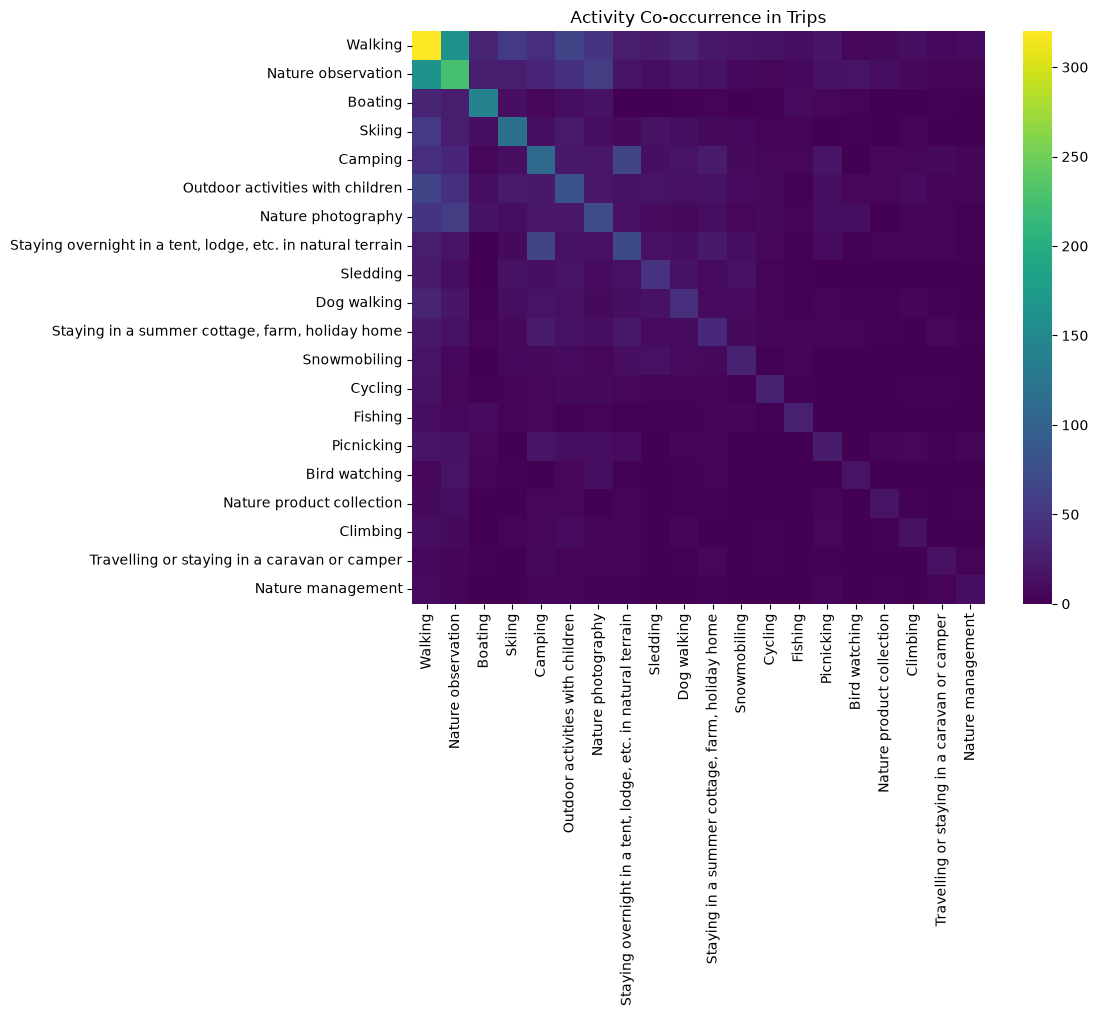

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Optional: keep only top activities
top_activities = (
    activity_matrix.sum()
    .sort_values(ascending=False)
    .head(20)
    .index
)

co_matrix_top = co_matrix.loc[top_activities, top_activities]

plt.figure(figsize=(12, 10))

sns.heatmap(
    co_matrix_top,
    cmap='viridis',
    square=True
)

plt.title('Activity Co-occurrence in Trips')
plt.tight_layout()
plt.savefig('figures/activity_cooccurrence_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

In [23]:
from sklearn.metrics import jaccard_score

activities = activity_matrix.columns

jaccard_results = []

for i, a1 in enumerate(activities):
    for a2 in activities[i+1:]:

        score = jaccard_score(
            activity_matrix[a1],
            activity_matrix[a2]
        )

        jaccard_results.append({
            'activity_1': a1,
            'activity_2': a2,
            'jaccard': score
        })

df_jaccard = pd.DataFrame(jaccard_results)

df_jaccard.sort_values(by='jaccard', ascending=False)

,activity_1,activity_2,jaccard
286,Frisbee golf,Golf,1.000000
91,Camping,"Staying overnight in a tent, lodge, etc. in na...",0.556522
440,Nature observation,Walking,0.425587
472,Orienteering,Running,0.400000
312,Gardening,Nature management,0.300000
...,...,...,...
238,Flying a drone,Gardening,0.000000
237,Flying a drone,Frisbee golf,0.000000
236,Flying a drone,Flying a kite,0.000000
234,Fishing,Treasure hunting,0.000000


## Trip temporal pattern

/tmp/xuleyi11/ipykernel_1753576/805700236.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[0], data=gdf_flickr_trip, x='year', palette='viridis')
/tmp/xuleyi11/ipykernel_1753576/805700236.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[1], data=gdf_flickr_trip, x='season', order=season_order, palette='coolwarm')
/tmp/xuleyi11/ipykernel_1753576/805700236.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[2], data=gdf_flickr_trip, x='day_of_week', order=day_order, palette='plasma')


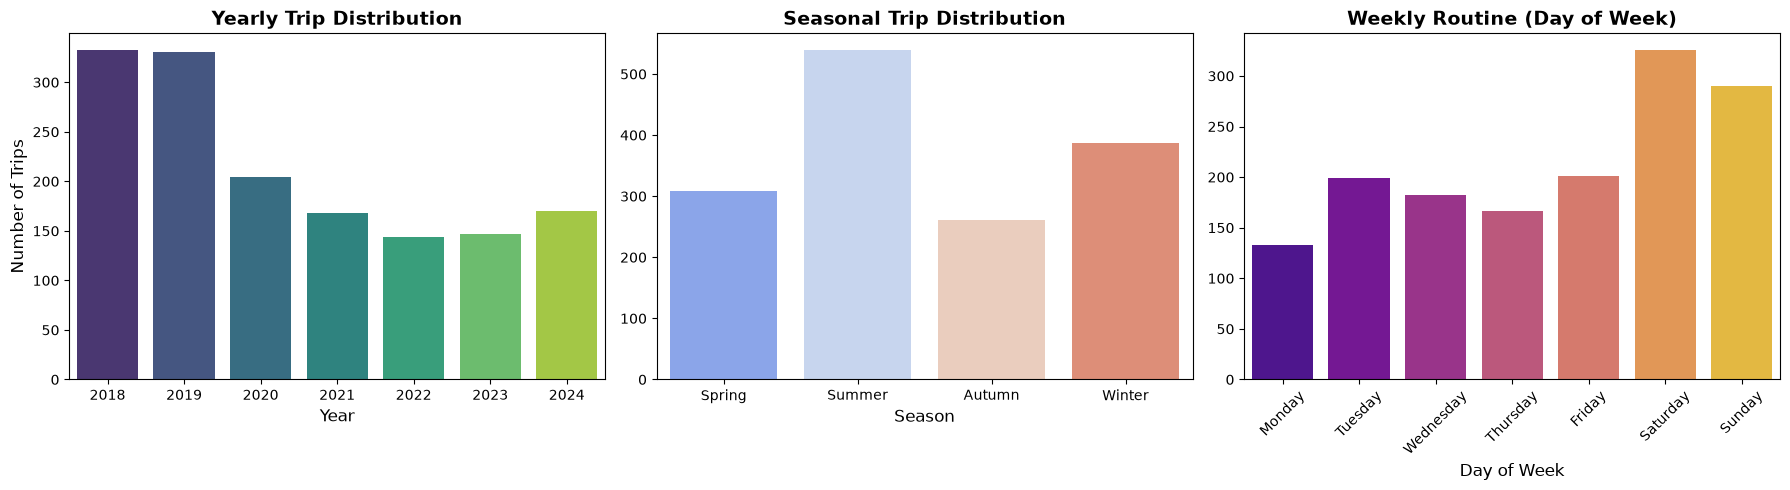

/tmp/xuleyi11/ipykernel_1753576/805700236.py:69: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['year_month'] = df['trip_start'].dt.to_period('M').astype(str)


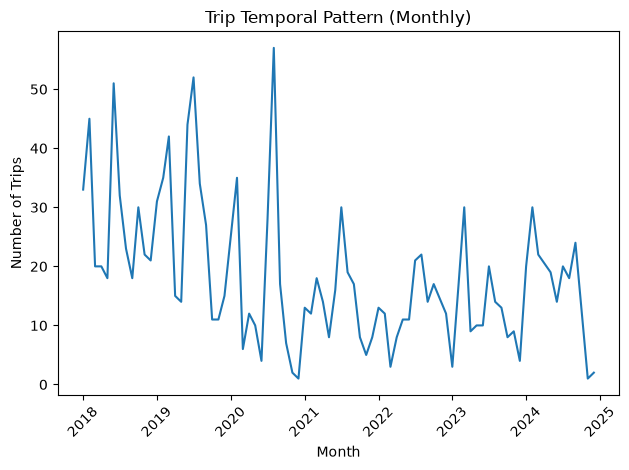

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure trip_start is parsed as a datetime object (handles timezones automatically)
gdf_flickr_trip['trip_start'] = pd.to_datetime(gdf_flickr_trip['trip_start'])

# 2. Extract Aggregated Temporal Features
gdf_flickr_trip['year'] = gdf_flickr_trip['trip_start'].dt.year
gdf_flickr_trip['month'] = gdf_flickr_trip['trip_start'].dt.month
gdf_flickr_trip['day_of_week'] = gdf_flickr_trip['trip_start'].dt.day_name()

# Define a function to map months to standard meteorological seasons
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

gdf_flickr_trip['season'] = gdf_flickr_trip['month'].apply(get_season)

# Set logical chronological ordering for categorical plots
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
season_order = ['Spring', 'Summer', 'Autumn', 'Winter']


# ==========================================
# DASHBOARD 1: Aggregated Cyclical Patterns
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot A: Yearly Distribution
sns.countplot(ax=axes[0], data=gdf_flickr_trip, x='year', palette='viridis')
axes[0].set_title('Yearly Trip Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Year', fontsize=12)
axes[0].set_ylabel('Number of Trips', fontsize=12)

# Plot B: Seasonal Distribution
sns.countplot(ax=axes[1], data=gdf_flickr_trip, x='season', order=season_order, palette='coolwarm')
axes[1].set_title('Seasonal Trip Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Season', fontsize=12)
axes[1].set_ylabel('')

# Plot C: Day of Week Distribution (Week-level Routine)
sns.countplot(ax=axes[2], data=gdf_flickr_trip, x='day_of_week', order=day_order, palette='plasma')
axes[2].set_title('Weekly Routine (Day of Week)', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Day of Week', fontsize=12)
axes[2].set_ylabel('')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('figures/trip_aggregated_patterns.png', dpi=300, bbox_inches='tight')
plt.show()


# ==========================================
# DASHBOARD 2: Continuous Weekly Timeline Trend
# ==========================================
# Group data by continuous year-week intervals
df = gdf_flickr_trip.copy()

df['trip_start'] = pd.to_datetime(df['trip_start'])

# Monthly temporal pattern
df['year_month'] = df['trip_start'].dt.to_period('M').astype(str)
ts = df.groupby('year_month').size().reset_index(name='trip_count')
ts['year_month'] = pd.to_datetime(ts['year_month'])
ts = ts.sort_values('year_month')

plt.figure()
plt.plot(ts['year_month'], ts['trip_count'])
plt.xticks(rotation=45)
plt.xlabel("Month")
plt.ylabel("Number of Trips")
plt.title("Trip Temporal Pattern (Monthly)")
plt.tight_layout()
plt.show()

## Spatial patterns

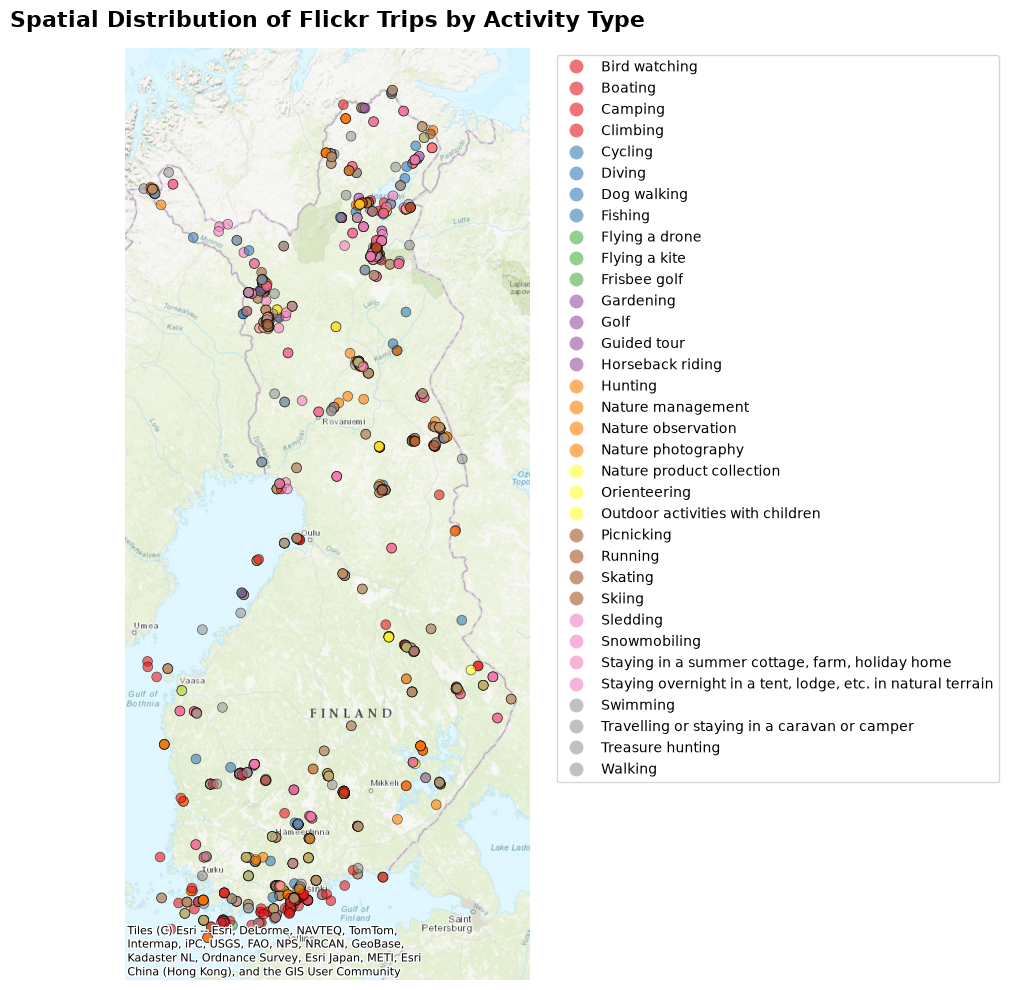

In [25]:
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

# 1. Double check / assign your current Coordinate Reference System (CRS) if not set.
# Looking at your sample data (e.g., POINT (361555.18 6690467.716)), this resembles ETRS89 / TM35FIN (EPSG:3067) often used in Finland.
# If it's already set, you can skip this if statement.
if gdf_flickr_trip.crs is None:
    # Replace 3067 with your actual EPSG code if different
    gdf_flickr_trip.set_crs(epsg=3067, inplace=True)

# 2. Contextily requires Web Mercator (EPSG:3857) to align points correctly with the basemap tiles
gdf_places_3857 = gdf_flickr_trip.to_crs(epsg=3857)

# 3. Plot the data
fig, ax = plt.subplots(figsize=(12, 10))

# Plot the trip points, color coded by activity
# Alpha is set to 0.6 to see overlapping points easily.
gdf_places_3857.plot(
    ax=ax, 
    column='activity', 
    categorical=True, 
    legend=True, 
    markersize=50, 
    cmap='Set1', 
    alpha=0.6, 
    edgecolor='k',
    linewidth=0.5,
    legend_kwds={
        'bbox_to_anchor': (1.05, 1), 
        'loc': 'upper left'
    }
)

# 4. Add the basemap background
# Using Esri World Topo Map tiles (OSM Mapnik is blocked on this network and CartoDB now needs an API key; Esri is open, no key).
ctx.add_basemap(ax=ax, source=ctx.providers.Esri.WorldTopoMap)

# 5. Clean up the layout
ax.set_title('Spatial Distribution of Flickr Trips by Activity Type', fontsize=16, fontweight='bold', pad=15)
ax.set_axis_off() # Hide the Web Mercator axis coordinates for a cleaner look

plt.tight_layout()
plt.savefig('figures/spatial_distribution_map.png', dpi=300, bbox_inches='tight')
plt.show()

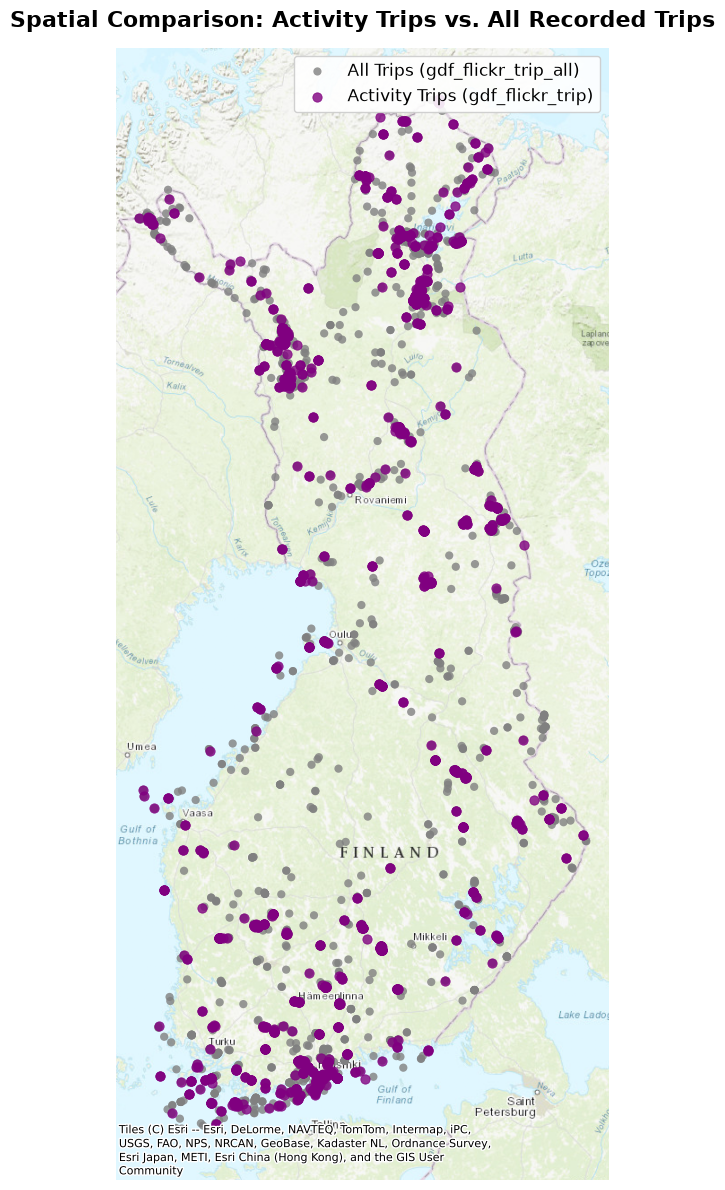

In [26]:
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

# 1. Handle Coordinate Reference System (CRS) matching
# Ensure both layers have their CRS declared before transforming
if gdf_flickr_trip.crs is None:
    gdf_flickr_trip.set_crs(epsg=3067, inplace=True) # Replace 3067 with your actual EPSG code

if gdf_flickr_trip_all.crs is None:
    gdf_flickr_trip_all.set_crs(epsg=3067, inplace=True)

# 2. Transform both layers to Web Mercator (EPSG:3857) for Contextily basemaps
gdf_trip_3857 = gdf_flickr_trip.to_crs(epsg=3857)
gdf_all_3857 = gdf_flickr_trip_all.to_crs(epsg=3857)

# 3. Initialize the plot
fig, ax = plt.subplots(figsize=(14, 12))

# 4. Plot Layer 1: All trips (Background / Grey)
gdf_all_3857.plot(
    ax=ax,
    color='grey',
    alpha=0.8,
    markersize=35,
    label='All Trips (gdf_flickr_trip_all)',
    edgecolor='none'
)

# 5. Plot Layer 2: Activity trips (Foreground / Purple)
gdf_trip_3857.plot(
    ax=ax,
    color='purple',
    alpha=0.8,
    markersize=45,
    label='Activity Trips (gdf_flickr_trip)',
    # edgecolor='black',
    linewidth=0.6,
    legend_kwds={
        'bbox_to_anchor': (1.05, 1), 
        'loc': 'upper left'
    }
)

# 6. Add a clean, muted basemap so the colors stand out clearly
# Esri World Topo Map is ideal here because it doesn't clash with your custom colors
ctx.add_basemap(ax=ax, source=ctx.providers.Esri.WorldTopoMap)

# 7. Map elements styling
ax.set_title('Spatial Comparison: Activity Trips vs. All Recorded Trips', fontsize=16, fontweight='bold', pad=15)
ax.set_axis_off()

# Force display of the legend matching our manual plot labels
plt.legend(loc='upper right', fontsize=12, frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.savefig('figures/trip_layers_comparison_map.png', dpi=300, bbox_inches='tight')
plt.show()